# Atividade prática de NLP — Classificação FAKE x REAL

**Curso:** Ciência de Dados — UNINTER  
**Disciplina:** Natural Language Processing  
**RU:** 4880041

Este notebook implementa a prática usando o corpus [Fake.Br](https://github.com/roneysco/Fake.br-Corpus), NLTK, TF-IDF e classificador supervisionado. Os resultados **não estão pré-preenchidos**: execute as células sequencialmente para obter as métricas e imagens reais.

**Etapas:** adquirir dados → alinhar pares → normalizar comprimento → pré-processar com NLTK → separar treino/teste → TF-IDF → treinar → medir → nuvens REAL/FAKE → respostas.

### Como os dados foram preparados

O corpus Fake.br contém notícias verdadeiras (REAL) e falsas (FAKE), organizadas em pares relacionados ao mesmo acontecimento.

Durante a preparação dos dados, foram adotados dois cuidados:

- **Divisão dos dados:** cada par de notícias foi mantido no mesmo conjunto, seja de treinamento ou de teste. Essa separação evita que o modelo utilize informações de uma notícia durante o treinamento e depois encontre uma notícia diretamente relacionada na avaliação.
- **Equilíbrio dos textos:** como as notícias verdadeiras costumam ser mais longas que as falsas, os textos maiores foram reduzidos para que cada par tivesse a mesma quantidade de palavras. Esse procedimento busca evitar que o modelo classifique as notícias apenas pelo tamanho, em vez de analisar seu conteúdo.

Esses procedimentos contribuem para uma avaliação mais confiável do classificador.

In [1]:
# 1. Bibliotecas necessárias
%pip -q install nltk scikit-learn pandas numpy matplotlib wordcloud

In [2]:
# 2. Importações, identificação e configuração
from pathlib import Path
from collections import Counter
import json
import re
import subprocess
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import regexp_tokenize
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from wordcloud import WordCloud

identificacao_4880041 = 'RU: 4880041'
SEMENTE = 42
np.random.seed(SEMENTE)
nltk.download('stopwords', quiet=True)
STOPWORDS = set(stopwords.words('portuguese'))
print(identificacao_4880041)

RU: 4880041


In [3]:
# 3. Baixar o corpus original da fonte oficial
repo = Path('/content/Fake.br-Corpus')
if not repo.exists():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/roneysco/Fake.br-Corpus.git', str(repo)], check=True)

pasta_real = repo / 'full_texts' / 'true'
pasta_fake = repo / 'full_texts' / 'fake'
assert pasta_real.is_dir() and pasta_fake.is_dir(), 'Pastas do corpus não encontradas.'
print('Corpus disponível em:', repo)

Corpus disponível em: /content/Fake.br-Corpus


### 4. Carregamento e organização das notícias

Os arquivos do corpus Fake.br são organizados em pares de notícias relacionadas, identificados pelo mesmo número nas pastas REAL e FAKE.

Nesta etapa, os textos são carregados e reunidos em uma tabela, mantendo seus identificadores e classificações originais.

In [4]:
# 4. Carregamento e organização das notícias por identificador
# Arquivos REAL e FAKE com o mesmo número formam um par de notícias relacionadas.
def arquivos_por_id(pasta):
    return {arquivo.stem: arquivo for arquivo in pasta.glob('*.txt')}

reais = arquivos_por_id(pasta_real)
falsas = arquivos_por_id(pasta_fake)
ids_pares = sorted(set(reais) & set(falsas), key=lambda x: int(x) if x.isdigit() else x)
assert ids_pares, 'Nenhum par encontrado. Verifique a estrutura do corpus.'

registros = []
for grupo_id in ids_pares:
    for rotulo, caminho in [('REAL', reais[grupo_id]), ('FAKE', falsas[grupo_id])]:
        texto = caminho.read_text(encoding='utf-8-sig', errors='strict')
        registros.append({'par_id': grupo_id, 'rotulo': rotulo, 'texto_original': texto})
dados = pd.DataFrame(registros)
print('Pares:', len(ids_pares), '| Notícias:', len(dados))
print(dados['rotulo'].value_counts().to_string())
assert len(dados) == len(ids_pares) * 2
assert dados['texto_original'].str.len().gt(0).all(), 'Existem textos vazios.'
dados.head(4)

Pares: 3600 | Notícias: 7200
rotulo
REAL    3600
FAKE    3600


,par_id,rotulo,texto_original
0,1,REAL,O Podemos decidiu expulsar o deputado federal...
1,1,FAKE,Kátia Abreu diz que vai colocar sua expulsão e...
2,2,REAL,Em evento realizado nesta terça-feira para div...
3,2,FAKE,Blog esquerdista dá a entender que reclamar de...


### 5. Normalização do comprimento dos textos

As notícias verdadeiras e falsas do corpus possuem comprimentos diferentes. Essa característica pode influenciar a classificação, fazendo com que o modelo identifique o tamanho do texto em vez de analisar seu conteúdo.

Para reduzir esse efeito, cada par REAL/FAKE é ajustado para ter a mesma quantidade de palavras. O texto mais longo é reduzido ao comprimento do menor, preservando a parte inicial de cada notícia.

Após o processamento, é realizada uma verificação para confirmar que os textos de cada par possuem comprimentos equivalentes.

In [5]:
# 5. Normalizar a quantidade de palavras entre os textos de cada par
# Os textos mais longos são truncados ao tamanho do menor texto de cada par.
def palavras(texto):
    return regexp_tokenize(texto, pattern=r'\w+', flags=re.UNICODE)

def truncar_par(grupo):
    quantidades = grupo['texto_original'].map(lambda t: len(palavras(t)))
    limite = quantidades.min()
    grupo = grupo.copy()
    grupo['tokens_antes'] = quantidades
    grupo['texto_equilibrado'] = grupo['texto_original'].map(
        lambda t: ' '.join(palavras(t)[:limite]))
    grupo['tokens_depois'] = limite
    return grupo

dados = pd.concat([truncar_par(g) for _, g in dados.groupby('par_id', sort=False)], ignore_index=True)
assert dados.groupby('par_id')['tokens_depois'].nunique().eq(1).all()
assert dados['texto_equilibrado'].str.strip().ne('').all()
print('Total de tokens originais por classe:')
print(dados.groupby('rotulo')['tokens_antes'].sum())
print('Total de tokens após truncamento por classe:')
print(dados.groupby('rotulo')['tokens_depois'].sum())

Total de tokens originais por classe:
rotulo
FAKE     668829
REAL    3983541
Name: tokens_antes, dtype: int64
Total de tokens após truncamento por classe:
rotulo
FAKE    657557
REAL    657557
Name: tokens_depois, dtype: int64


In [6]:
# 6. Pré-processamento com NLTK
# Conservamos letras/acento na tokenização; removemos stopwords e tokens de 1 caractere.
def preparar_texto(texto):
    tokens = regexp_tokenize(texto.lower(), pattern=r'[^\W\d_]+', flags=re.UNICODE)
    tokens = [t for t in tokens if len(t) > 1 and t not in STOPWORDS]
    return ' '.join(tokens)

dados['texto_limpo'] = dados['texto_equilibrado'].apply(preparar_texto)
assert dados['texto_limpo'].str.len().gt(0).all(), 'A limpeza produziu textos vazios.'
print('Exemplo (primeiros 200 caracteres):', dados.loc[0, 'texto_limpo'][:200])

Exemplo (primeiros 200 caracteres): podemos decidiu expulsar deputado federal carlos gaguim partido após polícia federal fazer buscas apreensões gabinete câmara legenda abre espaço receber senadora expulsa pmdb katia abreu meio nota leg


In [7]:
# 7. Divisão 75% treino / 25% teste por PAR, sem misturar pares entre conjuntos
particao = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMENTE)
idx_treino, idx_teste = next(particao.split(dados, dados['rotulo'], groups=dados['par_id']))
treino = dados.iloc[idx_treino].copy().reset_index(drop=True)
teste = dados.iloc[idx_teste].copy().reset_index(drop=True)
assert set(treino['par_id']).isdisjoint(set(teste['par_id']))
print('Treino:', len(treino), '| Teste:', len(teste))
print('Treino por classe:', treino['rotulo'].value_counts().to_dict())
print('Teste por classe:', teste['rotulo'].value_counts().to_dict())

Treino: 5400 | Teste: 1800
Treino por classe: {'REAL': 2700, 'FAKE': 2700}
Teste por classe: {'REAL': 900, 'FAKE': 900}


### 8. Vetorização TF-IDF e treinamento do classificador

Após o pré-processamento, os textos são transformados em representações numéricas utilizando TF-IDF, técnica que atribui pesos aos termos conforme sua importância nos documentos.

A vetorização considera palavras individuais, sequências de duas palavras (bigramas) e de três palavras (trigramas).

Essas características são utilizadas para treinar o classificador supervisionado LinearSVC, responsável por identificar padrões associados às notícias REAL e FAKE.

O desempenho é avaliado com os textos reservados para teste, utilizando a acurácia e a matriz de confusão.

In [8]:
# 8. TF-IDF e classificador supervisionado
# Ajustar o TF-IDF somente no treinamento evita vazamento estatístico do conjunto de teste.
vetorizador = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.95,
                             sublinear_tf=True, lowercase=False)
X_treino = vetorizador.fit_transform(treino['texto_limpo'])
X_teste = vetorizador.transform(teste['texto_limpo'])
modelo = LinearSVC(C=1.0, random_state=SEMENTE)
modelo.fit(X_treino, treino['rotulo'])
previsto = modelo.predict(X_teste)
acuracia = accuracy_score(teste['rotulo'], previsto)
print(f'Acurácia no conjunto de teste: {acuracia:.2%}')
print('Matriz de confusão (FAKE, REAL):')
print(confusion_matrix(teste['rotulo'], previsto, labels=['FAKE', 'REAL']))
print(classification_report(teste['rotulo'], previsto, digits=4, zero_division=0))
print('Critério > 85%:', 'ATENDIDO' if acuracia > 0.85 else 'NÃO ATENDIDO')
if acuracia > 0.93:
    print('Atenção: resultado > 93%. Revisar comprimento, duplicações e possíveis vieses antes de concluir.')

Acurácia no conjunto de teste: 92.94%
Matriz de confusão (FAKE, REAL):
[[842  58]
 [ 69 831]]
              precision    recall  f1-score   support

        FAKE     0.9243    0.9356    0.9299       900
        REAL     0.9348    0.9233    0.9290       900

    accuracy                         0.9294      1800
   macro avg     0.9295    0.9294    0.9294      1800
weighted avg     0.9295    0.9294    0.9294      1800

Critério > 85%: ATENDIDO


In [9]:
# 9. Contagem dos termos utilizados no treinamento por classe
# Cada palavra, bigrama ou trigrama distinto é contado uma única vez por classe,
# desde que esteja presente em pelo menos um texto de treinamento dessa classe.
termos = vetorizador.get_feature_names_out()

def frequencias_classe(rotulo):
    linhas = (treino['rotulo'].to_numpy() == rotulo)
    matriz = X_treino[linhas]
    soma_tfidf = np.asarray(matriz.sum(axis=0)).ravel()
    presenca = np.asarray((matriz > 0).sum(axis=0)).ravel()
    frequencias = {termos[i]: float(soma_tfidf[i]) for i in np.flatnonzero(presenca)}
    contagem = Counter(len(termos[i].split(' ')) for i in np.flatnonzero(presenca))
    return frequencias, {n: contagem.get(n, 0) for n in (1, 2, 3)}

freq_real, cont_real = frequencias_classe('REAL')
freq_fake, cont_fake = frequencias_classe('FAKE')
print('Termos presentes no treinamento após TF-IDF:')
print('REAL — unigramas, bigramas e trigramas:', cont_real)
print('FAKE — unigramas, bigramas e trigramas:', cont_fake)
print('Vocabulário total do modelo:', len(termos))

Termos presentes no treinamento após TF-IDF:
REAL — unigramas, bigramas e trigramas: {1: 19008, 2: 35338, 3: 14434}
FAKE — unigramas, bigramas e trigramas: {1: 19668, 2: 37054, 3: 14055}
Vocabulário total do modelo: 93217


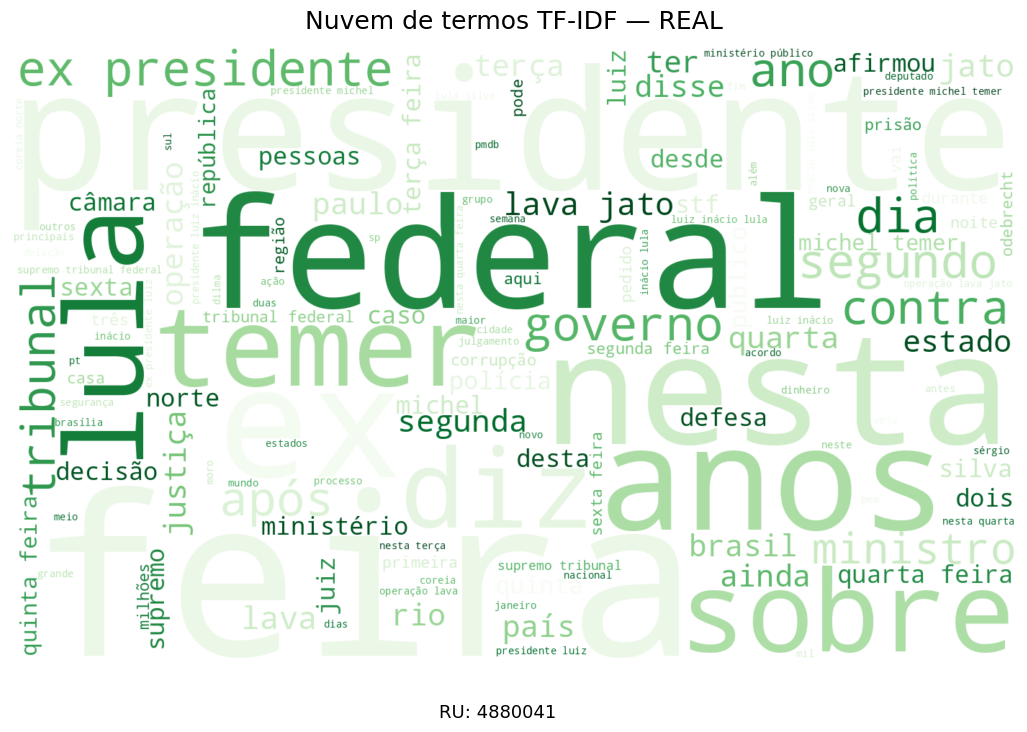

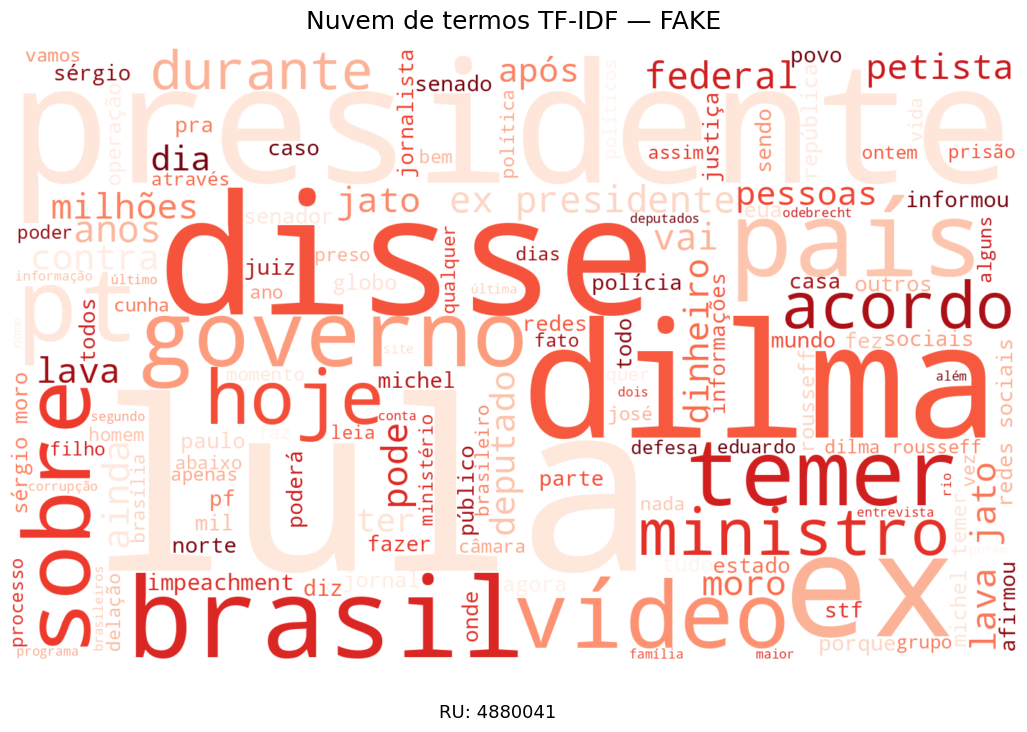

Arquivos gerados em: /content/resultados_nlp


In [10]:
# 10. Criar as nuvens de palavras (usando pesos TF-IDF, não frequência bruta)
saida = Path('/content/resultados_nlp')
saida.mkdir(exist_ok=True)

def criar_nuvem(frequencias, rotulo, arquivo, cmap):
    assert frequencias, f'Sem termos para a classe {rotulo}'
    nuvem = WordCloud(width=1400, height=850, background_color='white',
                      colormap=cmap, max_words=140, random_state=SEMENTE,
                      collocations=False).generate_from_frequencies(frequencias)
    fig, ax = plt.subplots(figsize=(13, 8))
    ax.imshow(nuvem, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Nuvem de termos TF-IDF — {rotulo}', fontsize=18, pad=14)
    fig.text(0.5, 0.04, identificacao_4880041, ha='center', fontsize=13)
    fig.savefig(saida / arquivo, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()

criar_nuvem(freq_real, 'REAL', 'nuvem_REAL_4880041.png', 'Greens')
criar_nuvem(freq_fake, 'FAKE', 'nuvem_FAKE_4880041.png', 'Reds')
print('Arquivos gerados em:', saida)

In [11]:
# 11. Respostas às questões da atividade
print('QUESTÃO 1 — REAL')
print(f'Unigramas: {cont_real[1]}; bigramas: {cont_real[2]}; trigramas: {cont_real[3]}.')
print(f'Acurácia do classificador no conjunto de teste: {acuracia:.2%}.')
print('\nQUESTÃO 2 — FAKE')
print(f'Unigramas: {cont_fake[1]}; bigramas: {cont_fake[2]}; trigramas: {cont_fake[3]}.')
print('Pré-processamento: truncamento alinhado por par, conversão para minúsculas,')
print('tokenização com NLTK, remoção de pontuação, números, stopwords e tokens curtos.')
print('Modelo: LinearSVC (máquina de vetores de suporte linear) com características TF-IDF (1 a 3 gramas).')

resumo = {
    'ru': '4880041',
    'quantidade_treino': len(treino), 'quantidade_teste': len(teste),
    'acuracia': float(acuracia), 'contagem_real': cont_real, 'contagem_fake': cont_fake,
    'modelo': 'LinearSVC', 'vetorizacao': 'TfidfVectorizer 1-3 gramas',
}
(saida / 'resultados.json').write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8')

QUESTÃO 1 — REAL
Unigramas: 19008; bigramas: 35338; trigramas: 14434.
Acurácia do classificador no conjunto de teste: 92.94%.

QUESTÃO 2 — FAKE
Unigramas: 19668; bigramas: 37054; trigramas: 14055.
Pré-processamento: truncamento alinhado por par, conversão para minúsculas,
tokenização com NLTK, remoção de pontuação, números, stopwords e tokens curtos.
Modelo: LinearSVC (máquina de vetores de suporte linear) com características TF-IDF (1 a 3 gramas).


330